# MF 731 Homework 6 - Stress testing a MSFT / AAPL portfolio

Code only. Write-up and discussion are in `hw6_written.ipynb`.

Market-cap-weighted portfolio of MSFT and AAPL as of 09/01/2016. A 5-sigma
one-day shock to AAPL (and a conditional 5-sigma shock to MSFT) is fed through
the EWMA mean and covariance, the next $K - 1 = 9$ days are simulated, and the
shocked 10-day losses are compared with the square-root-of-time VaR and the
regulatory capital estimated before the shock. Index (1) is MSFT, (2) is AAPL.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

ALPHA = 0.95
K = 10              # horizon in days
LAM = 0.97          # EWMA mean
THETA = 0.97        # EWMA covariance (not the dollar position theta_t)
V0 = 1_000_000
M_PATHS = 50_000
N_SIG = 5           # size of the shock, in standard deviations

plt.rcParams['figure.figsize'] = (11, 5)


def var_emp(losses, a):
    # VaR from a sample: the ceil(n*a)-th order statistic
    ls = np.sort(np.asarray(losses))
    n = len(ls)
    return ls[int(np.ceil(n * a)) - 1]

### Data

In [2]:
# Daily closes (split and dividend adjusted), saved to csv so this runs
# offline. To pull fresh data:
#     import yfinance as yf
#     yf.download(['MSFT', 'AAPL'], start='2011-09-01', end='2016-09-02',
#                 auto_adjust=True)['Close']
# (Yahoo's end date is exclusive, hence 09/02 to include 09/01.)
# AAPL split 7-for-1 in June 2014: unadjusted closes would show a fake
# -195% log return.
prices = pd.read_csv('stocks_daily.csv', parse_dates=['Date']).set_index('Date')
tickers = ['MSFT', 'AAPL']
prices = prices[tickers]

print('first five observations'); print(prices.head())
print('\nlast five observations'); print(prices.tail())
print('\nN =', len(prices), 'trading days,',
      prices.index[0].date(), '->', prices.index[-1].date())

first five observations
                 MSFT       AAPL
Date                            
2011-09-01  20.245007  11.396465
2011-09-02  19.928308  11.187697
2011-09-06  19.704319  11.357882
2011-09-07  20.082808  11.483206
2011-09-08  20.252731  11.489485

last five observations
                 MSFT       AAPL
Date                            
2016-08-26  51.528732  24.455643
2016-08-29  51.590897  24.428202
2016-08-30  51.404434  24.240677
2016-08-31  51.022594  24.263550
2016-09-01  51.138039  24.407616

N = 1259 trading days, 2011-09-01 -> 2016-09-01


In [3]:
# log returns X_s = ln(S_s / S_{s-1}), one row per day
X = np.log(prices / prices.shift(1)).dropna()
x_hist = X.values
n_hist = len(x_hist)
print('log returns:', n_hist, 'rows,', X.index[0].date(), '->', X.index[-1].date())
print(X.describe().loc[['mean', 'std', 'min', 'max']].T)

log returns: 1258 rows, 2011-09-02 -> 2016-09-01
          mean       std       min       max
MSFT  0.000737  0.014914 -0.121033  0.099413
AAPL  0.000605  0.016777 -0.131885  0.085022


### Market-cap weights and dollar positions $\theta_t = S_t \lambda_t$

In [4]:
mcap = pd.Series({'MSFT': 448.77, 'AAPL': 575.11})      # $ billion, 09/01/2016
w = (mcap / mcap.sum())[tickers]
pos = V0 * w.values         # theta_t: dollars in each stock, held as fixed shares

print('weights w_i'); print(w.round(6))
print('\ndollar positions theta_t:', pos.round(2))
print('check: total = %.2f' % pos.sum())

weights w_i
MSFT    0.438303
AAPL    0.561697
dtype: float64

dollar positions theta_t: [438303.32 561696.68]
check: total = 1000000.00


### Step 1. EWMA mean vector and covariance matrix

In [5]:
mu = np.zeros(2)
Sig = np.zeros((2, 2))
for x in x_hist:
    d = x - mu                                    # uses mu_s, before it is updated
    Sig = THETA * Sig + (1 - THETA) * np.outer(d, d)
    mu = LAM * mu + (1 - LAM) * x

sd = np.sqrt(np.diag(Sig))
rho = Sig[0, 1] / (sd[0] * sd[1])

print('EWMA estimates as of 09/01/2016 (for the return over 09/01 -> 09/02)')
print('mu    =', mu)
print('Sigma =\n', Sig)
print('daily sd       =', sd.round(6))
print('annualized vol =', (sd * np.sqrt(252)).round(4))
print('correlation    = %.4f' % rho)
print('\nweight left on (mu_0, Sigma_0) = 0 after %d steps: %.1e'
      % (n_hist, LAM**n_hist))

EWMA estimates as of 09/01/2016 (for the return over 09/01 -> 09/02)
mu    = [0.00140454 0.00116553]
Sigma =
 [[1.26271806e-04 3.32407835e-05]
 [3.32407835e-05 1.52044263e-04]]
daily sd       = [0.011237 0.012331]
annualized vol = [0.1784 0.1957]
correlation    = 0.2399

weight left on (mu_0, Sigma_0) = 0 after 1258 steps: 2.3e-17


### Step 2. VaR of the linearized loss before the shock

In [6]:
# L_lin = -theta' X  ~  N(-theta' mu, theta' Sigma theta)
z = norm.ppf(ALPHA)
loss_mean_1 = -pos @ mu
loss_sd_1 = np.sqrt(pos @ Sig @ pos)

VaR_1 = loss_mean_1 + loss_sd_1 * z
VaR_K = np.sqrt(K) * VaR_1              # square-root-of-time rule
reg_cap = 3 * VaR_K                     # regulatory capital, 3 x 10-day VaR

print('one-day loss: mean %.2f   sd %.2f' % (loss_mean_1, loss_sd_1))
print('VaR_0.95, 1-day            = %10.2f' % VaR_1)
print('VaR_0.95, %d-day (sqrt K)  = %10.2f' % (K, VaR_K))
print('regulatory capital 3 x VaR = %10.2f' % reg_cap)

one-day loss: mean -1270.29   sd 9412.54
VaR_0.95, 1-day            =   14211.95
VaR_0.95, 10-day (sqrt K)  =   44942.15
regulatory capital 3 x VaR =  134826.44


### Step 3. The shock

In [7]:
# (i) AAPL: 5 sigma down
x2 = mu[1] - N_SIG * sd[1]

# (ii) MSFT given X_(2) = x2: conditional normal, then a 5 sigma conditional shock
mu1_c = mu[0] + rho * sd[0] / sd[1] * (x2 - mu[1])
sd1_c = sd[0] * np.sqrt(1 - rho**2)
x1 = mu1_c - N_SIG * sd1_c

x_shock = np.array([x1, x2])
shock_loss = -pos @ x_shock

print('AAPL shock  x2 = %.6f   (%.2f%% simple return)' % (x2, 100 * np.expm1(x2)))
print('MSFT | AAPL: conditional mean %.6f, conditional sd %.6f' % (mu1_c, sd1_c))
print('MSFT shock  x1 = %.6f   (%.2f%% simple return)' % (x1, 100 * np.expm1(x1)))
print('  = %.2f unconditional sd below mu' % ((mu[0] - x1) / sd[0]))
print('linearized loss on the shock day = %.2f' % shock_loss)
print('  = %.2f x the one-day VaR, %.2f x the sqrt-rule 10-day VaR'
      % (shock_loss / VaR_1, shock_loss / VaR_K))

AAPL shock  x2 = -0.060488   (-5.87% simple return)
MSFT | AAPL: conditional mean -0.012074, conditional sd 0.010909
MSFT shock  x1 = -0.066619   (-6.44% simple return)
  = 6.05 unconditional sd below mu
linearized loss on the shock day = 63175.01
  = 4.45 x the one-day VaR, 1.41 x the sqrt-rule 10-day VaR


In [8]:
# (iii) EWMA update with the shocked returns -> mu_{t+2D}, Sigma_{t+2D}
d = x_shock - mu
Sig_2 = THETA * Sig + (1 - THETA) * np.outer(d, d)
mu_2 = LAM * mu + (1 - LAM) * x_shock
sd_2 = np.sqrt(np.diag(Sig_2))
rho_2 = Sig_2[0, 1] / (sd_2[0] * sd_2[1])

ann = np.sqrt(252)
print('                    before shock   after shock')
print('mu MSFT            %12.6f  %12.6f' % (mu[0], mu_2[0]))
print('mu AAPL            %12.6f  %12.6f' % (mu[1], mu_2[1]))
print('ann. vol MSFT      %12.4f  %12.4f' % (sd[0] * ann, sd_2[0] * ann))
print('ann. vol AAPL      %12.4f  %12.4f' % (sd[1] * ann, sd_2[1] * ann))
print('correlation        %12.4f  %12.4f' % (rho, rho_2))
print('one-day loss sd    %12.2f  %12.2f' % (loss_sd_1, np.sqrt(pos @ Sig_2 @ pos)))
print('one-day loss mean  %12.2f  %12.2f' % (loss_mean_1, -pos @ mu_2))

                    before shock   after shock
mu MSFT                0.001405     -0.000636
mu AAPL                0.001166     -0.000684
ann. vol MSFT            0.1784        0.2566
ann. vol AAPL            0.1957        0.2567
correlation              0.2399        0.6046
one-day loss sd         9412.54      14509.78
one-day loss mean      -1270.29        663.07


### Steps 4-5. Simulate days $2, \dots, K$ and the $K$-day loss

All $\hat M$ paths are run at once: `mus` is $\hat M \times 2$ and `Sigs` is
$\hat M \times 2 \times 2$, so every path carries its own EWMA state. Day 1 is
the same shock on every path. With `shock=False` day 1 is sampled like the
others, which gives the unstressed run to compare against.

In [9]:
def simulate(shock, rng, M=M_PATHS):
    mus = np.tile(mu, (M, 1))
    Sigs = np.tile(Sig, (M, 1, 1))
    X_sum = np.zeros((M, 2))
    corr_path = np.empty((M, K))           # correlation used on day k (k = 1..K)
    for k in range(1, K + 1):
        corr_path[:, k - 1] = Sigs[:, 0, 1] / np.sqrt(Sigs[:, 0, 0] * Sigs[:, 1, 1])
        if k == 1 and shock:
            Xk = np.tile(x_shock, (M, 1))
        else:
            # X = mu + C Z with C the Cholesky factor of each path's Sigma
            C = np.linalg.cholesky(Sigs)
            Z = rng.standard_normal((M, 2))
            Xk = mus + np.einsum('mij,mj->mi', C, Z)
        X_sum += Xk
        if k < K:                          # no update needed after day K
            dev = Xk - mus
            Sigs = THETA * Sigs + (1 - THETA) * np.einsum('mi,mj->mij', dev, dev)
            mus = LAM * mus + (1 - LAM) * Xk
    # L_lin = -theta_t' sum_k X_{t+kD}, shares held fixed
    losses = -X_sum @ pos
    return losses, corr_path


rng = np.random.default_rng(731)
l_shock, corr_shock = simulate(True, rng)
l_base, corr_base = simulate(False, rng)
print('simulated %d paths of %d days, shocked and unshocked' % (M_PATHS, K))

simulated 50000 paths of 10 days, shocked and unshocked


### (a)-(d) Shocked $K$-day losses

In [10]:
mean_shock = l_shock.mean()
VaR_shock = var_emp(l_shock, ALPHA)
n_var = np.sum(l_shock > VaR_K)
n_reg = np.sum(l_shock > reg_cap)
freq_var = 100 * n_var / M_PATHS
freq_reg = 100 * n_reg / M_PATHS

print('(a) average %d-day loss = %.2f' % (K, mean_shock))
print('(b) %d-day VaR_0.95 = %.2f   (order statistic %d of %d)'
      % (K, VaR_shock, int(np.ceil(M_PATHS * ALPHA)), M_PATHS))
print('(c) losses above the sqrt-rule VaR (%.2f): %d paths = %.3f%%'
      % (VaR_K, n_var, freq_var))
print('(d) losses above the regulatory capital (%.2f): %d paths = %.3f%%'
      % (reg_cap, n_reg, freq_reg))

print('\nshocked loss sd %.2f' % l_shock.std(ddof=1))
print('shocked VaR / pre-shock VaR_K = %.3f' % (VaR_shock / VaR_K))

(a) average 10-day loss = 69178.06
(b) 10-day VaR_0.95 = 149703.73   (order statistic 47500 of 50000)
(c) losses above the sqrt-rule VaR (44942.15): 34593 paths = 69.186%
(d) losses above the regulatory capital (134826.44): 4386 paths = 8.772%

shocked loss sd 49081.95
shocked VaR / pre-shock VaR_K = 3.331


### Comparison run without the shock (used in the figure)

In [11]:
print('unshocked run: mean %.2f   sd %.2f   VaR %.2f'
      % (l_base.mean(), l_base.std(ddof=1), var_emp(l_base, ALPHA)))
print('               %% > VaR_K %.3f%%   %% > reg %.3f%%'
      % (100 * np.mean(l_base > VaR_K), 100 * np.mean(l_base > reg_cap)))

unshocked run: mean -12676.90   sd 33732.15   VaR 42603.88
               % > VaR_K 4.378%   % > reg 0.006%


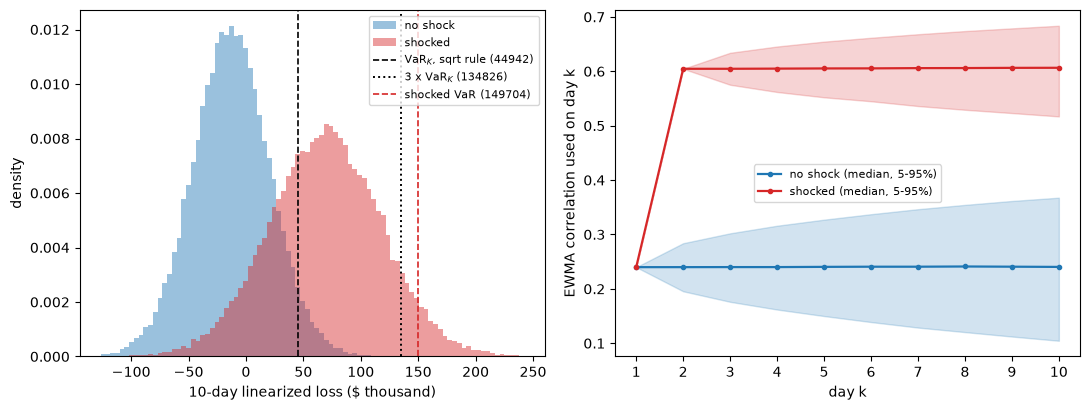

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))

kd = 1000                                   # plot in $ thousand
lo_edge = np.quantile(l_base, 0.0005)
hi_edge = np.quantile(l_shock, 0.9995)
bins = np.linspace(lo_edge, hi_edge, 90) / kd
ax[0].hist(l_base / kd, bins=bins, density=True, alpha=0.45, color='C0',
           label='no shock')
ax[0].hist(l_shock / kd, bins=bins, density=True, alpha=0.45, color='C3',
           label='shocked')
ax[0].axvline(VaR_K / kd, color='k', ls='--', lw=1.2,
              label='VaR$_K$, sqrt rule (%.0f)' % VaR_K)
ax[0].axvline(reg_cap / kd, color='k', ls=':', lw=1.4,
              label='3 x VaR$_K$ (%.0f)' % reg_cap)
ax[0].axvline(VaR_shock / kd, color='C3', ls='--', lw=1.2,
              label='shocked VaR (%.0f)' % VaR_shock)
ax[0].set_xlabel('%d-day linearized loss ($ thousand)' % K)
ax[0].set_ylabel('density')
ax[0].legend(fontsize=8)

days = np.arange(1, K + 1)
for cp, col, lab in [(corr_base, 'C0', 'no shock'), (corr_shock, 'C3', 'shocked')]:
    lo, med, hi = np.quantile(cp, [0.05, 0.5, 0.95], axis=0)
    ax[1].fill_between(days, lo, hi, color=col, alpha=0.2)
    ax[1].plot(days, med, color=col, lw=1.6, marker='o', ms=3,
               label=lab + ' (median, 5-95%)')
ax[1].set_xlabel('day k')
ax[1].set_ylabel('EWMA correlation used on day k')
ax[1].set_xticks(days)
ax[1].legend(fontsize=8)

fig.tight_layout()
plt.show()